# Which version of the website should you use?

## 📖 Background
You work for an early-stage startup in Germany. Your team has been working on a redesign of the landing page. The team believes a new design will increase the number of people who click through and join your site. 

They have been testing the changes for a few weeks and now they want to measure the impact of the change and need you to determine if the increase can be due to random chance or if it is statistically significant.

## ✅ Checklist before publishing
- Rename your workspace to make it descriptive of your work. N.B. you should leave the notebook name as notebook.ipynb.
- Remove redundant cells like the judging criteria, so the workbook is focused on your answers.
- Check that all the cells run without error.

## 💾 The data
The team assembled the following file:

#### Redesign test data
- "treatment" - "yes" if the user saw the new version of the landing page, no otherwise.
- "new_images" - "yes" if the page used a new set of images, no otherwise.
- "converted" - 1 if the user joined the site, 0 otherwise.

The control group is those users with "no" in both columns: the old version with the old set of images.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

design = pd.read_csv('./data/redesign.csv')
design.head()

,treatment,new_images,converted
0,yes,yes,0
1,yes,yes,0
2,yes,yes,0
3,yes,no,0
4,no,yes,0


## 1. Experimental Design & Descriptive Statistics
We map the users into 4 distinct testing variants to observe the raw baseline conversion metrics across groups.


In [6]:
def assign_group(row):
    if row['treatment'] == 'no' and row['new_images'] == 'no':
        return 'Control'
    elif row['treatment'] == 'no' and row['new_images'] == 'yes':
        return 'Only_Images'
    elif row['treatment'] == 'yes' and row['new_images'] == 'no':
        return 'Only_Page'
    else:
        return 'Page_and_Images'
design['group'] = design.apply(assign_group, axis = 1)

pivot_table = design.groupby(["treatment", "new_images"])["converted"].agg(["count", "sum", "mean"]).reset_index()
print(pivot_table)


  treatment new_images  count   sum      mean
0        no         no  10121  1084  0.107104
1        no        yes  10121  1139  0.112538
2       yes         no  10121  1215  0.120047
3       yes        yes  10121  1151  0.113724


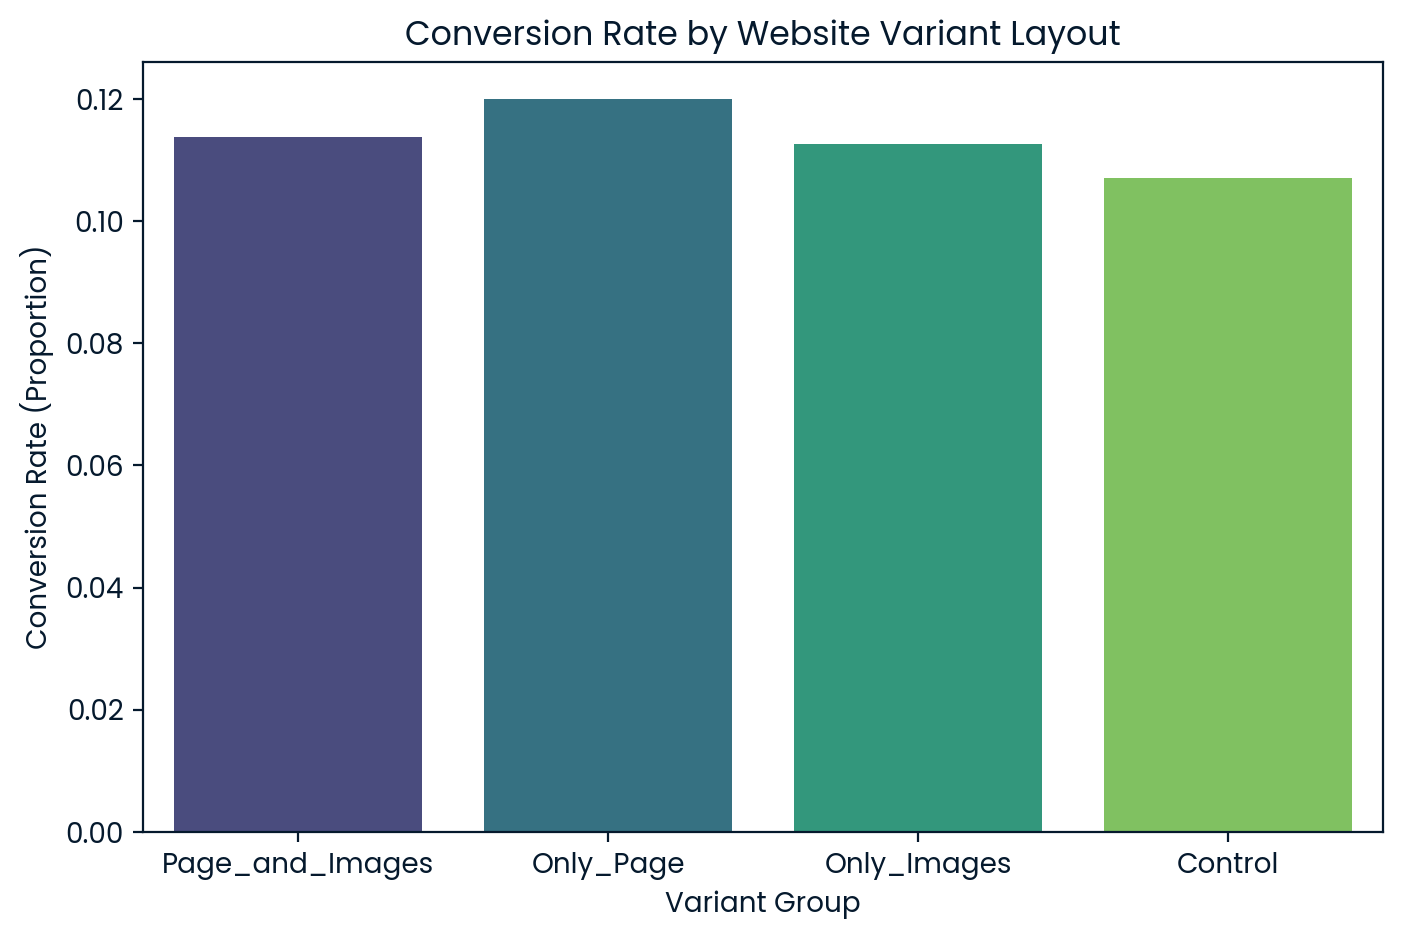

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=design, x='group', y='converted', ci=None, palette='viridis')
plt.title('Conversion Rate by Website Variant Layout')
plt.ylabel('Conversion Rate (Proportion)')
plt.xlabel('Variant Group')
plt.show()


In [7]:
expected, observed, stats = pg.chi2_independence(data = design, x = 'group', y = 'converted')
print(stats)

fixed_page = design[design['treatment'] == 'yes']
expected, observed, stats = pg.chi2_independence(data = fixed_page, x = 'new_images', y = 'converted')
print(stats)

# 1. Filter raw data to look ONLY at the Control group and the Only Page group
control_vs_page = design[design['group'].isin(['Control', 'Only_Page'])]

# 2. Run the chi-square test on these two groups
expected, observed, stats = pg.chi2_independence(data=control_vs_page, x='group', y='converted')

# 3. Print the results
print(stats[stats['test'] == 'pearson'])

                 test    lambda      chi2  dof      pval    cramer     power
0             pearson  1.000000  8.526057  3.0  0.036303  0.014512  0.685096
1        cressie-read  0.666667  8.522196  3.0  0.036367  0.014509  0.684876
2      log-likelihood  0.000000  8.515832  3.0  0.036471  0.014503  0.684514
3       freeman-tukey -0.500000  8.512246  3.0  0.036530  0.014500  0.684309
4  mod-log-likelihood -1.000000  8.509676  3.0  0.036573  0.014498  0.684162
5              neyman -2.000000  8.507581  3.0  0.036608  0.014496  0.684043
                 test    lambda      chi2  dof      pval    cramer     power
0             pearson  1.000000  1.899544  1.0  0.168129  0.009687  0.280798
1        cressie-read  0.666667  1.899588  1.0  0.168124  0.009687  0.280803
2      log-likelihood  0.000000  1.899743  1.0  0.168107  0.009688  0.280822
3       freeman-tukey -0.500000  1.899917  1.0  0.168088  0.009688  0.280843
4  mod-log-likelihood -1.000000  1.900141  1.0  0.168063  0.009689  0.280870

## 2. Statistical Verification (Omnibus Test)
We run a Chi-Square test across all four groups to determine if any statistically significant variance exists in our dataset.


In [8]:
expected, observed, stats = pg.chi2_independence(data = design, x = 'group', y = 'converted')
print(stats)


                 test    lambda      chi2  dof      pval    cramer     power
0             pearson  1.000000  8.526057  3.0  0.036303  0.014512  0.685096
1        cressie-read  0.666667  8.522196  3.0  0.036367  0.014509  0.684876
2      log-likelihood  0.000000  8.515832  3.0  0.036471  0.014503  0.684514
3       freeman-tukey -0.500000  8.512246  3.0  0.036530  0.014500  0.684309
4  mod-log-likelihood -1.000000  8.509676  3.0  0.036573  0.014498  0.684162
5              neyman -2.000000  8.507581  3.0  0.036608  0.014496  0.684043


## 3. Post-Hoc Analysis: Testing the New Images Asset
Since variance exists, we narrow our focus. Here, we evaluate whether adding new images provides a significant impact when the new page layout is fixed to 'yes'.

The Recommendation: Deploy the New Landing Page design but keep the Old Images.
The Business Impact: This combination increases website conversion rates from 10.71% to 12.00%, which represents a clean relative increase in performance without wasting resources on new image assets.

In [9]:
fixed_page = design[design['treatment'] == 'yes']
expected, observed, stats = pg.chi2_independence(data = fixed_page, x = 'new_images', y = 'converted')
print(stats)


                 test    lambda      chi2  dof      pval    cramer     power
0             pearson  1.000000  1.899544  1.0  0.168129  0.009687  0.280798
1        cressie-read  0.666667  1.899588  1.0  0.168124  0.009687  0.280803
2      log-likelihood  0.000000  1.899743  1.0  0.168107  0.009688  0.280822
3       freeman-tukey -0.500000  1.899917  1.0  0.168088  0.009688  0.280843
4  mod-log-likelihood -1.000000  1.900141  1.0  0.168063  0.009689  0.280870
5              neyman -2.000000  1.900737  1.0  0.167996  0.009690  0.280943


## 4. Final Validation: Redesign vs. Control Baseline
Our previous test showed that new images do not add significant value ($p = 0.168$). We now explicitly test our top performing variant (`Only_Page`) against the original `Control` baseline to confirm its standalone significance.


In [10]:
control_vs_page = design[design['group'].isin(['Control', 'Only_Page'])]
# 2. Run the chi-square test on these two groups
expected, observed, stats = pg.chi2_independence(data=control_vs_page, x='group', y='converted')
# 3. Print the results
print(stats[stats['test'] == 'pearson'])

      test  lambda      chi2  dof     pval    cramer     power
0  pearson     1.0  8.292894  1.0  0.00398  0.020241  0.821155
